In [2]:
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.patches import Rectangle

df = pd.read_csv("../../datasets/heart.csv")

print("Dataset shape:", df.shape)
print("Columns:", df.columns.tolist())

Dataset shape: (1025, 14)
Columns: ['age', 'sex', 'cp', 'trestbps', 'chol', 'fbs', 'restecg', 'thalach', 'exang', 'oldpeak', 'slope', 'ca', 'thal', 'target']


In [3]:
missing_grid = []

for row_index in range(len(df)):
    row_status = []

    for col in df.columns:
        value = df.iloc[row_index][col]

        if pd.isna(value):
            row_status.append(1)
        else:
            row_status.append(0)

    missing_grid.append(row_status)

missing_count = sum(sum(row) for row in missing_grid)

print("Total missing values:", missing_count)
print("Rows checked:", len(missing_grid))
print("Columns checked:", len(df.columns))

Total missing values: 0
Rows checked: 1025
Columns checked: 14


In [4]:
missing_by_column = {}

for col_index, col in enumerate(df.columns):
    count = 0

    for row in missing_grid:
        count += row[col_index]

    missing_by_column[col] = count

for col, count in missing_by_column.items():
    print(f"{col}: {count} missing values")

age: 0 missing values
sex: 0 missing values
cp: 0 missing values
trestbps: 0 missing values
chol: 0 missing values
fbs: 0 missing values
restecg: 0 missing values
thalach: 0 missing values
exang: 0 missing values
oldpeak: 0 missing values
slope: 0 missing values
ca: 0 missing values
thal: 0 missing values
target: 0 missing values


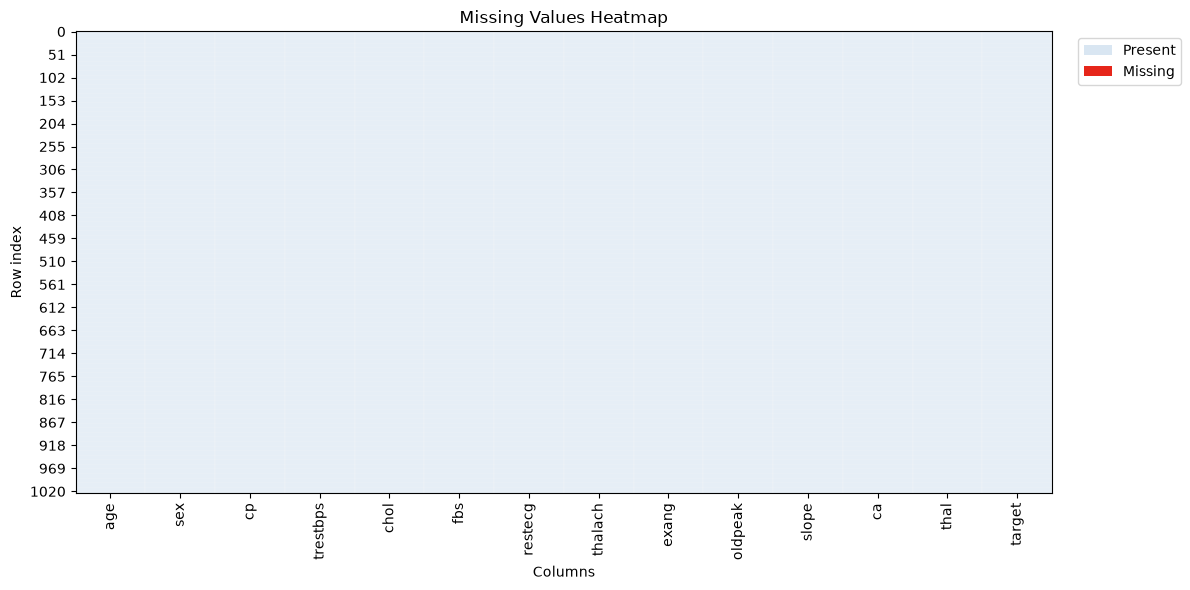

In [5]:
fig, ax = plt.subplots(figsize=(12, 6))

for row_index, row in enumerate(missing_grid):
    for col_index, status in enumerate(row):
        if status == 1:
            color = (0.9, 0.15, 0.1)
        else:
            color = (0.85, 0.9, 0.95)

        cell = Rectangle(
            (col_index, row_index),
            1,
            1,
            facecolor=color,
            edgecolor="white",
            linewidth=0.15
        )

        ax.add_patch(cell)

ax.set_xlim(0, len(df.columns))
ax.set_ylim(0, len(df))
ax.invert_yaxis()

ax.set_xticks([i + 0.5 for i in range(len(df.columns))])
ax.set_xticklabels(df.columns, rotation=90)

# Keep the full dataset grid, but label only selected row numbers
step = max(1, len(df) // 20)
row_ticks = list(range(0, len(df), step))

ax.set_yticks([i + 0.5 for i in row_ticks])
ax.set_yticklabels(row_ticks)

ax.set_xlabel("Columns")
ax.set_ylabel("Row index")
ax.set_title("Missing Values Heatmap")

present_patch = Rectangle((0, 0), 1, 1, facecolor=(0.85, 0.9, 0.95))
missing_patch = Rectangle((0, 0), 1, 1, facecolor=(0.9, 0.15, 0.1))

ax.legend(
    [present_patch, missing_patch],
    ["Present", "Missing"],
    loc="upper left",
    bbox_to_anchor=(1.02, 1)
)

plt.tight_layout()
plt.show()

In [6]:
total_cells = len(df) * len(df.columns)

if total_cells > 0:
    missing_percentage = missing_count / total_cells * 100
else:
    missing_percentage = 0

print("Total data cells:", total_cells)
print("Missing cells:", missing_count)
print(f"Missing percentage: {missing_percentage:.2f}%")

if missing_count == 0:
    print("No missing values found in the dataset.")
else:
    print("Missing values are highlighted in red in the heatmap.")

Total data cells: 14350
Missing cells: 0
Missing percentage: 0.00%
No missing values found in the dataset.


# Task 14: Missing Values Heatmap

## Objective
To visualize missing values using a manually constructed grid and custom color mapping without using Seaborn heatmap or Matplotlib's image plotting functions.

## Methodology
1. Loaded the Heart Disease dataset.
2. Checked each data cell for missing values.
3. Constructed a binary grid where 1 represents missing data and 0 represents present data.
4. Counted missing values by column and calculated the overall missing percentage.
5. Drew each grid cell using Matplotlib Rectangle patches and custom colors.
6. Added labels and a legend to distinguish present and missing values.

## Conclusion
A custom grid-based heatmap was implemented to examine missing-value patterns. Missing cells are highlighted separately from present cells. If no missing values exist, the heatmap confirms that all inspected data cells are present.

The actual missing-value counts and percentage should be reported using the notebook outputs.
